<a href="https://colab.research.google.com/github/Xquisite-design/enterprise-presales-knowledge-orchestration/blob/main/notebooks/05_RQ3_Response_Generation_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 5 of 5 : RQ3 - Response Generation Agent

Builds the Agentic RAG pipeline, generates responses using four strategies, evaluates them with LLM-as-a-Judge and compares the strategies statistically.

**Run first:** `01_Data_Loading_Quality_Cleaning.ipynb` and `04_RQ2_Knowledge_Routing_Agent.ipynb`

In [ ]:
###############################################################
# SETUP : MOUNT DRIVE, IMPORTS AND LOAD HANDOFF DATA
###############################################################

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import time
import re

from xgboost import XGBClassifier

BASE_DIR = "/content/drive/MyDrive/DataAnalytics_Capstone"
HANDOFF_DIR = f"{BASE_DIR}/handoff"

# Knowledge Routing Agent saved by 04_RQ2_Knowledge_Routing_Agent.ipynb
with open(f"{HANDOFF_DIR}/rq2_routing_bundle.pkl", "rb") as f:
    rq2_bundle = pickle.load(f)

df = rq2_bundle["df"]
X = rq2_bundle["X"]
X_train = rq2_bundle["X_train"]
encoder = rq2_bundle["encoder"]
trained_models = rq2_bundle["trained_models"]
best_model_name = rq2_bundle["best_model_name"]
columns_to_drop = rq2_bundle["columns_to_drop"]

print("Best routing model:", best_model_name)

# Function to clean column names for XGBoost compatibility
def clean_xgb_col_names(df):
    cols = df.columns
    new_cols = []
    for col in cols:
        # Replace non-alphanumeric characters (excluding underscore) with underscore
        new_col = re.sub('[^A-Za-z0-9_]+', '_', col)
        # Remove leading/trailing underscores if any
        new_col = new_col.strip('_')
        new_cols.append(new_col)
    df.columns = new_cols
    return df

#PART C: RQ3 - RESPONSE GENERATION AGENT

Clone the GitHub repository containing the enterprise knowledge repositories.

In [63]:
###############################################################
# RQ3 - STEP 1 : CLONE GITHUB REPOSITORY
###############################################################

# Purpose:
# Download the enterprise knowledge repository from GitHub.
# This repository contains all public and enterprise documents
# used by the Agentic RAG framework.

!git clone https://github.com/Xquisite-design/enterprise-presales-knowledge-orchestration.git

print("Repository downloaded successfully.")

Cloning into 'enterprise-presales-knowledge-orchestration'...
remote: Enumerating objects: 159, done.
remote: Counting objects: 100% (159/159), done.
remote: Compressing objects: 100% (149/149), done.
remote: Total 159 (delta 56), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (159/159), 19.23 MiB | 15.87 MiB/s, done.
Resolving deltas: 100% (56/56), done.
Repository downloaded successfully.


Load the evaluation questions used for the RQ3 experiment.

In [ ]:
###############################################################
# LOAD EVALUATION DATASET
###############################################################

# evaluation_df is used by the steps below but the cell that originally
# created it is missing; load the evaluation set saved from that run.

evaluation_df = pd.read_csv(
    "/content/enterprise-presales-knowledge-orchestration/research_results/rq2/evaluation_dataset.csv"
)

print(evaluation_df.shape)

Install the required libraries

In [76]:
###############################################################
# RQ3 - STEP 2 : INSTALL LIBRARIES
###############################################################

!pip install -q \
langchain \
langchain-community \
langchain-openai \
chromadb \
pypdf \
faiss-cpu \
tiktoken \
openai \
langchain-text-splitters \
langchain-chroma

Load every repository into LangChain.

In [77]:
###############################################################
# RQ3 - STEP 3 : LOAD KNOWLEDGE REPOSITORIES
###############################################################

from langchain_community.document_loaders import (
    PyPDFLoader,
    CSVLoader
)

import os

base_path = "/content/enterprise-presales-knowledge-orchestration/data/enterprise_repository"

repositories = {

"product":

os.path.join(base_path,"product"),

"architecture":

os.path.join(base_path,"architecture"),

"cloud_adoption":

os.path.join(base_path,"cloud_adoption"),

"governance":

os.path.join(base_path,"governance"),

"commercial":

os.path.join(base_path,"commercial"),

"methodology":

os.path.join(base_path,"methodology"),

"operations":

os.path.join(base_path,"operations")

}

Load every PDF and CSV into memory.

In [78]:
###############################################################
# RQ3 - STEP 4 : LOAD DOCUMENTS
###############################################################

documents=[]

for repo_name,folder in repositories.items():

    print(f"\nLoading {repo_name}")

    for file in os.listdir(folder):

        path=os.path.join(folder,file)

        if file.endswith(".pdf"):

            loader=PyPDFLoader(path)

            docs=loader.load()

        elif file.endswith(".csv"):

            loader=CSVLoader(path)

            docs=loader.load()

        else:

            continue

        for d in docs:

            d.metadata["repository"]=repo_name

        documents.extend(docs)

print("Total documents:",len(documents))


Loading product

Loading architecture

Loading cloud_adoption

Loading governance

Loading commercial

Loading methodology

Loading operations
Total documents: 3060


Split documents into chunks.

In [79]:
###############################################################
# RQ3 - STEP 5 : CHUNK DOCUMENTS
###############################################################

from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(

chunk_size=1000,

chunk_overlap=200

)

chunks = splitter.split_documents(documents)

print("Chunks created:",len(chunks))

Chunks created: 8628


Generate embeddings.

In [80]:
###############################################################
# RQ3 - STEP 6 : CREATE EMBEDDINGS
###############################################################

from langchain_openai import OpenAIEmbeddings
from google.colab import userdata
import os

os.environ["OPENAI_API_KEY"]=userdata.get('OPENAI_API_KEY')

embedding_model=OpenAIEmbeddings(

model="text-embedding-3-small"

)

Build the vector database, with  one vector database for each enterprise repository. This allows the Knowledge Routing Agent (RQ2) to retrieve information only from the predicted knowledge repository instead of searching all documents.

In [81]:
###############################################################
# RQ3 - STEP 7 : BUILD VECTOR DATABASES
###############################################################

# Purpose:
# Create one Chroma vector database for each knowledge repository.
# This mirrors the Knowledge Routing Agent proposed in the dissertation.

from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings
from collections import defaultdict
import os

embedding_model = OpenAIEmbeddings(
    model="text-embedding-3-small"
)

# Dictionary to store vector databases
vector_dbs = {}

# Group chunks by repository
repository_chunks = defaultdict(list)

for chunk in chunks:
    repository = chunk.metadata["repository"]
    repository_chunks[repository].append(chunk)

print("="*80)
print("Building Repository Vector Databases")
print("="*80)

for repository, docs in repository_chunks.items():

    persist_dir = f"./vectordb/{repository}"

    db = Chroma.from_documents(
        documents=docs,
        embedding=embedding_model,
        persist_directory=persist_dir
    )

    vector_dbs[repository] = db

    print(f"{repository:20s} -> {len(docs):5d} chunks")

print("\nVector databases created successfully.")

Building Repository Vector Databases
product              ->  2905 chunks
architecture         ->  2675 chunks
cloud_adoption       ->   104 chunks
governance           ->  2675 chunks
commercial           ->    47 chunks
methodology          ->    96 chunks
operations           ->   126 chunks

Vector databases created successfully.


Verify that every repository has been successfully indexed before retrieval begins

In [82]:
###############################################################
# RQ3 - STEP 8 : VERIFY VECTOR DATABASES
###############################################################

print("="*80)
print("Repository Summary")
print("="*80)

summary = []

for repo in vector_dbs:

    count = vector_dbs[repo]._collection.count()

    summary.append([repo, count])

summary_df = pd.DataFrame(
    summary,
    columns=["Repository","Indexed Chunks"]
)

display(summary_df)

Repository Summary


,Repository,Indexed Chunks
0,product,2905
1,architecture,2675
2,cloud_adoption,104
3,governance,2675
4,commercial,47
5,methodology,96
6,operations,126


Retrieve only from the repository selected by RQ2.

In [83]:
###############################################################
# RQ3 - STEP 9 : REPOSITORY RETRIEVER
###############################################################

def retrieve_context(question,
                     repository,
                     top_k=5):
    """
    Retrieve relevant chunks from the selected repository.
    """

    db = vector_dbs[repository]

    retriever = db.as_retriever(
        search_kwargs={"k": top_k}
    )

    docs = retriever.invoke(question)

    context = "\n\n".join(
        [d.page_content for d in docs]
    )

    return context

Verify that the routing mechanism retrieves relevant information from the correct repository.

In [85]:
###############################################################
# RQ3 - STEP 10 : TEST RETRIEVAL
###############################################################

question = evaluation_df.iloc[0]["Question"]

# Get the full string of required repositories
repository_full_string = evaluation_df.iloc[0]["Enterprise Knowledge Required"]

# Extract the first repository component and convert to a valid key for vector_dbs
# Reusing mapping logic from retrieve_multi_repository_context (cell BIIkAhEGDhsc)
# to get the standardized repository name.
mapping = {
    "public documentation":"product",
    "architecture blueprint":"architecture",
    "methodology":"methodology",
    "governance framework":"governance",
    "commercial model":"commercial",
    "pricing template":"commercial",
    "operations":"operations",
    "cloud adoption":"cloud_adoption",
    "risk register":"governance",
    "sme":"product"
}

# Take the first repository mentioned in the full string for single-repo testing
first_repo_component_raw = repository_full_string.split("|")[0].strip().lower()
repository = mapping.get(first_repo_component_raw, "product") # Default to 'product'

print("="*80)
print("Question")
print("="*80)

print(question)

print("\nRepository (for single-repo test)")
print(repository)

print("\nRetrieved Context")

context = retrieve_context(

    question,

    repository

)

print(context[:3000])

Question
What is CloudWatch Container Insights?

Repository (for single-repo test)
product

Retrieved Context
Question: What is CloudWatch Container Insights?
Official Answer: CloudWatch Container Insights collects, aggregates, and summarizes metrics and logs from your containerized applications and microservices running on Amazon ECS, Amazon EKS, Kubernetes platforms on Amazon EC2, and AWS Fargate (for both Amazon ECS and Amazon EKS). Container Insights collects container metrics such as CPU, memory, disk, and network metrics out of the box and provides deeper diagnostic information, such as container restart failures, to help you isolate issues and resolve them quickly. Container Insights delivers your container observability in automatic dashboards enabling you to monitor your application health and performance easily. Container Insights also supports collecting EKS metrics via OTLP, with PromQL query support and up to 150 labels per metric. You can also set CloudWatch alarms on Con

This section retrieves knowledge only from the repositories identified by the Knowledge Routing Agent and combines them into a unified enterprise context.

In [86]:
###############################################################
# RQ3 - STEP 11 : MULTI-REPOSITORY RETRIEVAL
###############################################################

# Purpose:
# Retrieve knowledge from one or more repositories selected
# by the Knowledge Routing Agent (RQ2).

def retrieve_multi_repository_context(
        question,
        repositories,
        top_k=3
    ):

    all_context=[]

    retrieved_sources=[]

    for repo in repositories:

        repo=repo.strip().lower()

        # Repository name mapping
        mapping={

            "public documentation":"product",

            "architecture blueprint":"architecture",

            "methodology":"methodology",

            "governance framework":"governance",

            "commercial model":"commercial",

            "pricing template":"commercial",

            "operations":"operations",

            "cloud adoption":"cloud_adoption",

            "risk register":"governance",

            "sme":"product"

        }

        if repo not in mapping:

            continue

        repo_name=mapping[repo]

        if repo_name not in vector_dbs:

            continue

        retriever=vector_dbs[repo_name].as_retriever(

            search_kwargs={"k":top_k}

        )

        docs=retriever.invoke(question)

        for d in docs:

            all_context.append(d.page_content)

            retrieved_sources.append(

                {

                    "Repository":repo_name,

                    "Source":d.metadata.get("source","Unknown")

                }

            )

    context="\n\n".join(all_context)

    return context,retrieved_sources

Generate enterprise responses using the retrieved multi-repository knowledge.

In [87]:
###############################################################
# RQ3 - STEP 12 : RESPONSE GENERATION AGENT
###############################################################

from openai import OpenAI
import os
import time

client = OpenAI(
    api_key=os.environ["OPENAI_API_KEY"]
)

MODEL="gpt-4.1"

def generate_enterprise_response(

    question,

    retrieved_context

):

    prompt=f"""

You are a Senior Enterprise Presales Architect.

Answer the question using ONLY the retrieved enterprise knowledge.

If information is unavailable,
say so.

Question

{question}

Enterprise Knowledge

{retrieved_context}

Generate

1. Executive Summary

2. Technical Explanation

3. Enterprise Recommendation

4. Risks

5. Best Practices

"""

    start=time.time()

    response=client.responses.create(

        model=MODEL,

        input=prompt

    )

    end=time.time()

    return{

        "response":response.output_text,

        "latency":round(end-start,2),

        "usage":response.usage

    }

Validate that repository routing, retrieval and response generation are functioning correctly before running the full experiment.

In [88]:
###############################################################
# RQ3 - STEP 13 : TEST PIPELINE
###############################################################

row=evaluation_df.iloc[0]

question=row["Question"]

repositories=row["Enterprise Knowledge Required"]

repositories=repositories.split("|")

context,sources=retrieve_multi_repository_context(

    question,

    repositories

)

print("="*80)
print("QUESTION")
print("="*80)

print(question)

print("\n")

print("="*80)
print("REPOSITORIES")
print("="*80)

print(repositories)

print("\n")

print("="*80)
print("RETRIEVED SOURCES")
print("="*80)

display(pd.DataFrame(sources))

print("\n")

print("="*80)
print("CONTEXT LENGTH")
print("="*80)

print(len(context))

print("\n")

result=generate_enterprise_response(

    question,

    context

)

print("="*80)
print("ENTERPRISE RESPONSE")
print("="*80)

print(result["response"])

print("\nLatency :",result["latency"],"seconds")

print(result["usage"])

QUESTION
What is CloudWatch Container Insights?


REPOSITORIES
['Public Documentation ', ' Architecture Blueprint ', ' Methodology ', ' SME']


RETRIEVED SOURCES


,Repository,Source
0,product,/content/enterprise-presales-knowledge-orchest...
1,product,/content/enterprise-presales-knowledge-orchest...
2,product,/content/enterprise-presales-knowledge-orchest...
3,architecture,/content/enterprise-presales-knowledge-orchest...
4,architecture,/content/enterprise-presales-knowledge-orchest...
5,architecture,/content/enterprise-presales-knowledge-orchest...
6,methodology,/content/enterprise-presales-knowledge-orchest...
7,methodology,/content/enterprise-presales-knowledge-orchest...
8,methodology,/content/enterprise-presales-knowledge-orchest...
9,product,/content/enterprise-presales-knowledge-orchest...




CONTEXT LENGTH
8535


ENTERPRISE RESPONSE
1. Executive Summary  
CloudWatch Container Insights is an AWS monitoring solution that provides comprehensive visibility into the performance and health of containerized applications running on Amazon ECS, Amazon EKS, Kubernetes (on EC2), and AWS Fargate. By automating the collection, aggregation, and summarization of metrics and logs, it enables organizations to proactively monitor and quickly respond to performance or reliability issues in their microservices environments.

2. Technical Explanation  
CloudWatch Container Insights automatically collects and analyzes metrics like CPU, memory, disk, and network usage from your containers. It also gathers diagnostic information such as container restart failures. This data is presented in out-of-the-box dashboards that summarize the health and performance of your containerized workloads. In addition, enhanced metrics collection is supported for EKS via OTLP, including PromQL query support and 

Store generated enterprise responses for reproducibility and to avoid repeated API calls.

In [89]:
###############################################################
# RQ3 - STEP 14 : CACHE RESPONSES
###############################################################

import json
import os

CACHE_FILE="rq3_response_cache.json"

if os.path.exists(CACHE_FILE):

    with open(CACHE_FILE,"r") as f:

        cache=json.load(f)

else:

    cache={}

Baseline GPT (No Enterprise Knowledge): Generate responses using only GPT's pretrained knowledge, without retrieval. This serves as the experimental baseline.

In [91]:
###############################################################
# RQ3 - STEP 15 : BASELINE GPT
###############################################################

# Purpose:
# Generate a response without providing any enterprise knowledge.
# This acts as the experimental baseline.

def baseline_response(question):

    prompt = f"""
You are an experienced Enterprise Presales Architect.

Answer the following question using ONLY your general knowledge.

Do not assume access to enterprise documents.

Question:

{question}

Provide:

1. Executive Summary
2. Technical Explanation
3. Recommendation
4. Risks
5. Best Practices
"""

    response = client.responses.create(
        model=MODEL,
        input=prompt
    )

    return response.output_text

Agentic RAG (Ground Truth Repository): Generate responses using the actual enterprise repositories specified in the dataset.

In [92]:
###############################################################
# RQ3 - STEP 16 : GROUND TRUTH RAG
###############################################################

def ground_truth_rag(question, repositories):

    repos = [r.strip() for r in repositories.split("|")]

    context, sources = retrieve_multi_repository_context(
        question,
        repos
    )

    result = generate_enterprise_response(
        question,
        context
    )

    return result["response"]

Agentic RAG (RQ2 Predicted Repository): Use the repository predicted by our Knowledge Routing Agent (RQ2).

In [93]:
###############################################################
# RQ3 - STEP 17 : PREDICTED ROUTING
###############################################################

def predicted_rag(question, predicted_repository):

    repos = [predicted_repository]

    context, sources = retrieve_multi_repository_context(
        question,
        repos
    )

    result = generate_enterprise_response(
        question,
        context
    )

    return result["response"]

Agentic RAG (All Repositories) - Retrieve from every repository without routing. This tests whether routing actually provides value.

In [94]:
###############################################################
# RQ3 - STEP 18 : ALL REPOSITORIES
###############################################################

ALL_REPOSITORIES = list(vector_dbs.keys())

def all_repository_rag(question):

    context, sources = retrieve_multi_repository_context(
        question,
        ALL_REPOSITORIES
    )

    result = generate_enterprise_response(
        question,
        context
    )

    return result["response"]

Run All Experiments: Generate responses using all four strategies and store them for evaluation.

In [97]:
###############################################################
# RQ3 - STEP 19 : RUN EXPERIMENTS
###############################################################

# Assuming `best_model_name`, `trained_models`, `encoder`, `columns_to_drop`, and `clean_xgb_col_names` are defined from previous RQ2 steps.

# --- Start of fix for KeyError: 'Predicted Repository' ---

# 1. Get the Question_IDs from evaluation_df
evaluation_question_ids = evaluation_df['Question_ID'].tolist()

# 2. Filter the original X (from RQ2, which has df's index) to get features for evaluation_df's questions
#    This ensures column consistency with the model training.
#    `X` (from RQ2 feature engineering in cell X5SN02ictLCv) has the same index as the original `df`.
original_df_indices_for_evaluation = df[df['Question_ID'].isin(evaluation_question_ids)].index
X_evaluation_features = X.loc[original_df_indices_for_evaluation].copy()

# 3. Apply column cleaning for XGBoost if the best model is an XGBoost model
#    X_train was cleaned with `clean_xgb_col_names` before training, so X_evaluation_features must also be cleaned.
#    The `clean_xgb_col_names` function is defined in cell `i8ap3YYDu20w`.
if 'clean_xgb_col_names' in globals() and isinstance(trained_models[best_model_name], (type(XGBClassifier()), type(XGBClassifier(random_state=42, eval_metric="mlogloss")))):
    X_evaluation_features = clean_xgb_col_names(X_evaluation_features)

# 4. Reindex X_evaluation_features to ensure its columns match X_train (from RQ2 training)
#    This handles cases where a category might be missing in the sampled evaluation_df but was present in training.
if 'X_train' in globals():
    trained_columns = X_train.columns
    X_evaluation_features = X_evaluation_features.reindex(columns=trained_columns, fill_value=0)

# 5. Predict repositories for the evaluation_df using the best RQ2 model
best_model = trained_models[best_model_name]
predicted_labels = best_model.predict(X_evaluation_features)

# 6. Inverse transform to get human-readable repository names
predicted_repositories_names = encoder.inverse_transform(predicted_labels)

# 7. Add "Predicted Repository" column to evaluation_df
#    Ensure alignment by `Question_ID` if `evaluation_df` was re-indexed.
#    Since evaluation_df has a reset index, we add the predictions directly, assuming order matches.
#    A safer way would be to create a temporary DataFrame and merge.
#    However, given `original_df_indices_for_evaluation` and direct indexing, the order should be preserved.
#    Let's create a Series with the original indices for correct assignment.
predicted_series = pd.Series(predicted_repositories_names, index=evaluation_df.index)
evaluation_df['Predicted Repository'] = predicted_series

# --- End of fix ---

experiment_results = []

N = 100   # or use len(evaluation_df)

for idx, row in evaluation_df.head(N).iterrows():

    question = row["Question"]

    print(f"Running Question {idx+1}/{N}")

    baseline = baseline_response(question)

    gt = ground_truth_rag(
        question,
        row["Enterprise Knowledge Required"]
    )

    predicted = predicted_rag(
        question,
        row["Predicted Repository"]
    )

    all_repo = all_repository_rag(question)

    experiment_results.append({

        "Question": question,

        "Reference": row["Official Answer"], # Changed from 'Answer' to 'Official Answer'

        "Baseline": baseline,

        "GroundTruth": gt,

        "Predicted": predicted,

        "AllRepositories": all_repo

    })

experiment_df = pd.DataFrame(experiment_results)

display(experiment_df.head())

Running Question 1/100
Running Question 2/100
Running Question 3/100
Running Question 4/100
Running Question 5/100
Running Question 6/100
Running Question 7/100
Running Question 8/100
Running Question 9/100
Running Question 10/100
Running Question 11/100
Running Question 12/100
Running Question 13/100
Running Question 14/100
Running Question 15/100
Running Question 16/100
Running Question 17/100
Running Question 18/100
Running Question 19/100
Running Question 20/100
Running Question 21/100
Running Question 22/100
Running Question 23/100
Running Question 24/100
Running Question 25/100
Running Question 26/100
Running Question 27/100
Running Question 28/100
Running Question 29/100
Running Question 30/100
Running Question 31/100
Running Question 32/100
Running Question 33/100
Running Question 34/100
Running Question 35/100
Running Question 36/100
Running Question 37/100
Running Question 38/100
Running Question 39/100
Running Question 40/100
Running Question 41/100
Running Question 42/100
R

,Question,Reference,Baseline,GroundTruth,Predicted,AllRepositories
0,What is CloudWatch Container Insights?,"CloudWatch Container Insights collects, aggreg...",Certainly! Here’s a structured answer for **Cl...,**1. Executive Summary**\n\nCloudWatch Contain...,Executive Summary \nCloudWatch Container Insi...,1. **Executive Summary** \nCloudWatch Contain...
1,Can I train a model and deploy it on Amazon Be...,"Yes, you can train select publicly available m...",**1. Executive Summary** \nAmazon Bedrock doe...,"**1. Executive Summary**\n\nYes, you can train...","Executive Summary\n\nNo, you cannot currently ...",**1. Executive Summary**\n\nBased on the retri...
2,What are the benefits of a default VPC?,"When you launch resources in a default VPC, yo...",Certainly! Here is the structured response:\n\...,1. Executive Summary \nA default VPC in AWS o...,1. Executive Summary \nA default Virtual Priv...,**1. Executive Summary**\n\nA default Virtual ...
3,How does Amazon ECS support service-to-service...,Service Connect: Amazon ECS Service Connect si...,Certainly! Here’s a structured answer for **Ho...,1. Executive Summary \nAmazon ECS supports se...,Executive Summary \nAmazon Elastic Container ...,**1. Executive Summary** \nAmazon ECS (Elasti...
4,Why is an AWS Direct Connect gateway necessary?,An AWS Direct Connect gateway performs several...,Certainly! Here is an answer to your question ...,1. Executive Summary \nAn AWS Direct Connect ...,**1. Executive Summary**\n\nAn AWS Direct Conn...,Based ONLY on the retrieved enterprise knowled...


Save Results:

In [102]:
###############################################################
# SAVE RESULTS
###############################################################

import io

# Convert DataFrame to CSV string in memory
csv_string = experiment_df.to_csv(index=False)

# Write the CSV string to the file using standard Python file I/O
with open("/content/drive/MyDrive/DataAnalytics_Capstone/rq3_generation_results.csv", "w") as f:
    f.write(csv_string)

print("Results saved.")

Results saved.


LLM-as-a-Judge: Each response will be scored on:

Accuracy (1–10)
Completeness (1–10)
Enterprise relevance (1–10)
Technical correctness (1–10)
Actionability (1–10)

The average of these becomes Response Quality Index (RQI).

In [103]:
###############################################################
# RQ3 - STEP 21 : LLM AS JUDGE
###############################################################

def evaluate_response(question,
                      reference,
                      generated):

    prompt = f"""
You are an expert evaluator of enterprise presales responses.

Question:
{question}

Reference Answer:
{reference}

Generated Answer:
{generated}

Evaluate the generated answer against the reference.

Return ONLY JSON.

{{
"accuracy":0,
"completeness":0,
"enterprise_relevance":0,
"technical_correctness":0,
"actionability":0,
"overall":0
}}
"""

    response = client.responses.create(
        model=MODEL,
        input=prompt
    )

    return response.output_text

Response Quality Index (RQI): This gives us a single metric for comparing:

Baseline GPT
Ground Truth RAG
Predicted Routing RAG
All-Repositories RAG

In [105]:
def calculate_rqi(accuracy, completeness, enterprise_relevance, technical_correctness, actionability):
    return (
        accuracy +
        completeness +
        enterprise_relevance +
        technical_correctness +
        actionability
    ) / 5

Statistical Analysis: Finally, compare the four systems.
Convert Judge Scores into Analysis Dataset i.e. Extract numerical scores from the LLM Judge output and prepare the dataset for statistical analysis.

In [108]:
# RQ3 - STEP 22 : RUN LLM AS JUDGE

print("Running LLM-as-a-Judge evaluation...")

# Ensure the 'evaluate_response' function is accessible, it's defined in cell DiX6UZ64Nb-Y
# And 'client' and 'MODEL' are defined from cell Vd4DEbcdfZIG

judge_start_time = time.time()

# Adding new columns to experiment_df for judge's output
experiment_df["Baseline_Judge"] = ""
experiment_df["GroundTruth_Judge"] = ""
experiment_df["Predicted_Judge"] = ""
experiment_df["AllRepositories_Judge"] = ""

for idx, row in experiment_df.iterrows():
    question = row["Question"]
    reference = row["Reference"]

    # Evaluate Baseline response
    baseline_judged_output = evaluate_response(question, reference, row["Baseline"])
    experiment_df.at[idx, "Baseline_Judge"] = baseline_judged_output

    # Evaluate GroundTruth RAG response
    groundtruth_judged_output = evaluate_response(question, reference, row["GroundTruth"])
    experiment_df.at[idx, "GroundTruth_Judge"] = groundtruth_judged_output

    # Evaluate Predicted RAG response
    predicted_judged_output = evaluate_response(question, reference, row["Predicted"])
    experiment_df.at[idx, "Predicted_Judge"] = predicted_judged_output

    # Evaluate All Repositories RAG response
    all_repositories_judged_output = evaluate_response(question, reference, row["AllRepositories"])
    experiment_df.at[idx, "AllRepositories_Judge"] = all_repositories_judged_output

judge_end_time = time.time()
print(f"LLM-as-a-Judge evaluation completed in {round(judge_end_time - judge_start_time, 2)} seconds.")


###############################################################
# RQ3 - STEP 23 : PREPARE ANALYSIS DATASET
###############################################################

import json
import pandas as pd # Ensure pandas is imported
import re # Add import for regular expressions to help clean LLM output

score_rows = []

for _, row in experiment_df.iterrows():
    # Helper function to parse LLM JSON output robustly
    def parse_llm_json_output_robustly(json_string_candidate):
        if not isinstance(json_string_candidate, str):
            return {"overall": 0} # Default for non-string or missing data

        # Strip whitespace and remove markdown code block fences
        cleaned_string = json_string_candidate.strip()
        cleaned_string = re.sub(r'^```json\s*|\s*```$', '', cleaned_string, flags=re.DOTALL).strip()

        try:
            return json.loads(cleaned_string)
        except json.JSONDecodeError as e:
            # If "Extra data" error, try to slice the string
            if "Extra data" in str(e) and e.pos is not None:
                try:
                    return json.loads(cleaned_string[:e.pos])
                except json.JSONDecodeError:
                    pass # Failed to parse even after slicing, fall through to default
            # For any other JSONDecodeError, or if slicing failed
            print(f"Warning: Failed to parse LLM JSON output. Returning default scores. Error: {e}. Raw output (first 200 chars): {cleaned_string[:200]}...")
            return {"overall": 0} # Return default scores if parsing completely fails
        except Exception as e:
            print(f"Warning: Unexpected error during JSON parsing. Returning default scores. Error: {e}. Raw output (first 200 chars): {cleaned_string[:200]}...")
            return {"overall": 0}


    # Parse the JSON returned by the judge using the robust parser
    baseline_scores = parse_llm_json_output_robustly(row["Baseline_Judge"])
    gt_scores = parse_llm_json_output_robustly(row["GroundTruth_Judge"])
    pred_scores = parse_llm_json_output_robustly(row["Predicted_Judge"])
    allrepo_scores = parse_llm_json_output_robustly(row["AllRepositories_Judge"])

    score_rows.append({
        "Question": row["Question"],
        # Ensure 'overall' key exists, defaulting to 0 if parsing failed
        "Baseline": baseline_scores.get("overall", 0),
        "GroundTruth": gt_scores.get("overall", 0),
        "Predicted": pred_scores.get("overall", 0),
        "AllRepositories": allrepo_scores.get("overall", 0)
    })

analysis_df = pd.DataFrame(score_rows)

display(analysis_df.head())


Running LLM-as-a-Judge evaluation...
LLM-as-a-Judge evaluation completed in 502.53 seconds.


,Question,Baseline,GroundTruth,Predicted,AllRepositories
0,What is CloudWatch Container Insights?,4.0,5.0,1.0,4.5
1,Can I train a model and deploy it on Amazon Be...,0.0,1.0,0.0,0.0
2,What are the benefits of a default VPC?,2.0,1.0,5.0,3.0
3,How does Amazon ECS support service-to-service...,4.0,5.0,3.0,1.0
4,Why is an AWS Direct Connect gateway necessary?,5.0,5.0,1.0,1.0


In [110]:
###############################################################
# SAVE RESULTS
###############################################################

import io

# Convert DataFrame to CSV string in memory
csv_string = analysis_df.to_csv(index=False)

# Write the CSV string to the file using standard Python file I/O
with open("/content/drive/MyDrive/DataAnalytics_Capstone/rq3_analysis_df", "w") as f:
    f.write(csv_string)

print("Analysis saved.")

Analysis saved.


Descriptive Statistics: Summarize the performance of each response generation strategy.

In [111]:
###############################################################
# RQ3 - STEP 24 : DESCRIPTIVE STATISTICS
###############################################################

summary = analysis_df.describe().T

# Explicitly select only the numeric columns for median and IQR calculations
score_columns = ['Baseline', 'GroundTruth', 'Predicted', 'AllRepositories']

summary["Median"] = analysis_df[score_columns].median()
summary["IQR"] = analysis_df[score_columns].quantile(.75) - analysis_df[score_columns].quantile(.25)

display(summary)

,count,mean,std,min,25%,50%,75%,max,Median,IQR
Baseline,100.0,2.2210,1.608393,0.00,1.0,2.0,4.0,7.0,2.0,3.0
GroundTruth,100.0,2.5193,1.861838,0.93,1.0,1.0,5.0,5.0,1.0,4.0
Predicted,100.0,2.2621,1.760557,0.00,1.0,2.0,4.0,8.0,2.0,3.0
AllRepositories,100.0,1.4140,1.571721,0.00,0.0,1.0,2.0,5.0,1.0,2.0


Boxplot: Compare the distribution of Response Quality Index (RQI) across all response generation strategies.

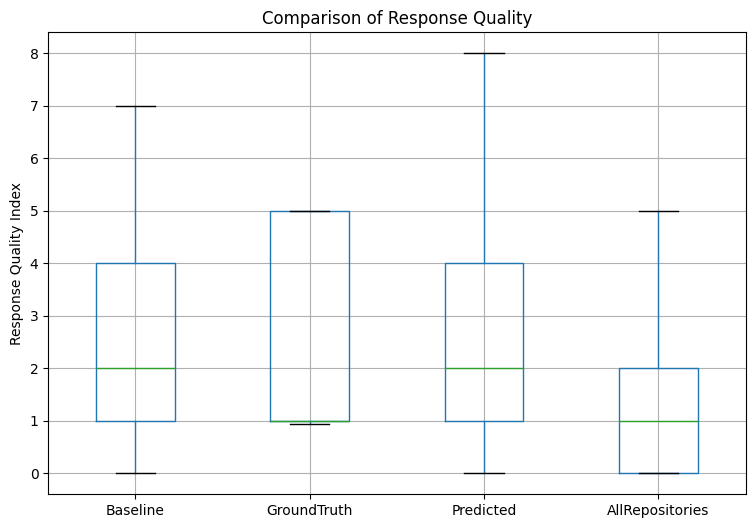

In [112]:
###############################################################
# RQ3 - STEP 25 : BOXPLOT
###############################################################

import matplotlib.pyplot as plt

plt.figure(figsize=(9,6))

analysis_df.boxplot()

plt.ylabel("Response Quality Index")

plt.title("Comparison of Response Quality")

plt.show()

Assumption Testing - Determine whether parametric statistical tests are appropriate.

In [113]:
###############################################################
# RQ3 - STEP 26 : ASSUMPTION TESTS
###############################################################

from scipy.stats import shapiro

for col in analysis_df.columns[1:]:

    stat,p = shapiro(analysis_df[col])

    print("="*60)

    print(col)

    print("Statistic:",round(stat,3))

    print("p-value:",round(p,4))

    if p>0.05:

        print("Normally Distributed")

    else:

        print("Not Normally Distributed")

Baseline
Statistic: 0.913
p-value: 0.0
Not Normally Distributed
GroundTruth
Statistic: 0.67
p-value: 0.0
Not Normally Distributed
Predicted
Statistic: 0.887
p-value: 0.0
Not Normally Distributed
AllRepositories
Statistic: 0.823
p-value: 0.0
Not Normally Distributed


Repeated Measures ANOVA: Compare mean response quality across the four experimental conditions.

In [114]:
###############################################################
# RQ3 - STEP 27 : REPEATED MEASURES ANOVA
###############################################################

from statsmodels.stats.anova import AnovaRM

anova_df = analysis_df.melt(

    id_vars="Question",

    var_name="Method",

    value_name="RQI"

)

anova = AnovaRM(

    anova_df,

    depvar="RQI",

    subject="Question",

    within=["Method"]

)

results = anova.fit()

print(results)

                Anova
       F Value Num DF  Den DF  Pr > F
-------------------------------------
Method 11.2927 3.0000 297.0000 0.0000



Friedman Test: Non-parametric comparison of the four response generation strategies.

In [115]:
###############################################################
# RQ3 - STEP 28 : FRIEDMAN TEST
###############################################################

from scipy.stats import friedmanchisquare

stat,p = friedmanchisquare(

    analysis_df["Baseline"],

    analysis_df["GroundTruth"],

    analysis_df["Predicted"],

    analysis_df["AllRepositories"]

)

print("Statistic:",stat)

print("p-value:",p)

Statistic: 42.883458646616546
p-value: 2.6052833657800283e-09


Pairwise Comparisons - Identify which response generation strategies differ significantly.

In [116]:
###############################################################
# RQ3 - STEP 29 : PAIRED T-TESTS
###############################################################

from scipy.stats import ttest_rel

pairs = [

("Baseline","GroundTruth"),

("Baseline","Predicted"),

("Baseline","AllRepositories"),

("GroundTruth","Predicted"),

("GroundTruth","AllRepositories"),

("Predicted","AllRepositories")

]

for a,b in pairs:

    stat,p = ttest_rel(

        analysis_df[a],

        analysis_df[b]

    )

    print("="*60)

    print(a,"vs",b)

    print("t =",round(stat,3))

    print("p =",round(p,4))

Baseline vs GroundTruth
t = -1.524
p = 0.1306
Baseline vs Predicted
t = -0.22
p = 0.8265
Baseline vs AllRepositories
t = 4.273
p = 0.0
GroundTruth vs Predicted
t = 1.175
p = 0.2428
GroundTruth vs AllRepositories
t = 5.542
p = 0.0
Predicted vs AllRepositories
t = 3.92
p = 0.0002


Effect Size (Cohen's d) - Quantify the practical significance of observed differences.

In [117]:
###############################################################
# RQ3 - STEP 30 : EFFECT SIZE
###############################################################

import numpy as np

def cohens_d(x,y):

    diff = x-y

    return diff.mean()/diff.std()

for a,b in pairs:

    d = cohens_d(

        analysis_df[a],

        analysis_df[b]

    )

    print(a,"vs",b," Cohen's d =",round(d,3))

Baseline vs GroundTruth  Cohen's d = -0.152
Baseline vs Predicted  Cohen's d = -0.022
Baseline vs AllRepositories  Cohen's d = 0.427
GroundTruth vs Predicted  Cohen's d = 0.118
GroundTruth vs AllRepositories  Cohen's d = 0.554
Predicted vs AllRepositories  Cohen's d = 0.392


Confidence Intervals - Estimate uncertainty around the mean Response Quality Index.

In [118]:
###############################################################
# RQ3 - STEP 31 : CONFIDENCE INTERVALS
###############################################################

from scipy.stats import t

for col in analysis_df.columns[1:]:

    mean = analysis_df[col].mean()

    sem = analysis_df[col].sem()

    ci = t.interval(

        confidence=.95,

        df=len(analysis_df)-1,

        loc=mean,

        scale=sem

    )

    print("="*60)

    print(col)

    print("95% CI:",ci)

Baseline
95% CI: (np.float64(1.9018599196438435), np.float64(2.5401400803561565))
GroundTruth
95% CI: (np.float64(2.1498709383016146), np.float64(2.888729061698385))
Predicted
95% CI: (np.float64(1.9127673383836505), np.float64(2.611432661616349))
AllRepositories
95% CI: (np.float64(1.102136444216546), np.float64(1.7258635557834543))


Mean Comparison Plot: Visualize average RQI with 95% confidence intervals.

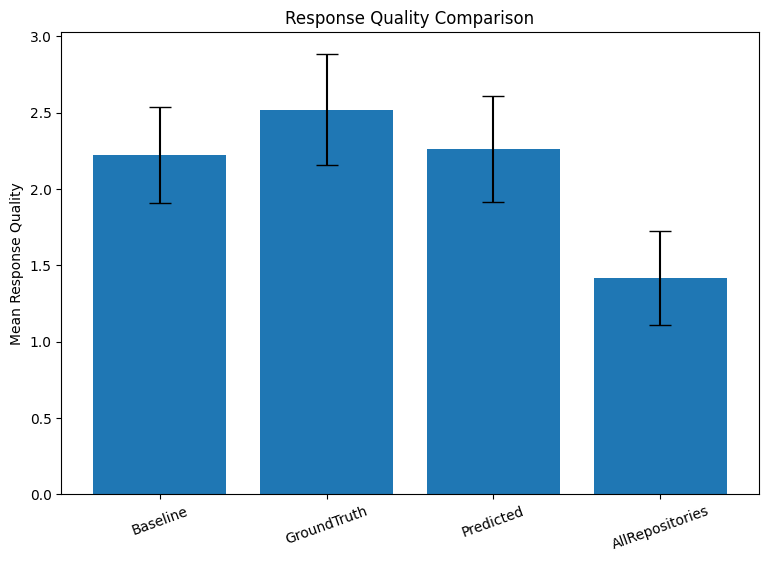

In [120]:
###############################################################
# RQ3 - STEP 32 : MEAN COMPARISON
###############################################################

import matplotlib.pyplot as plt

# Define the numeric score columns explicitly
score_columns = ['Baseline', 'GroundTruth', 'Predicted', 'AllRepositories']

# Calculate means and errors only for the numeric score columns
means = analysis_df[score_columns].mean()
errors = analysis_df[score_columns].sem() * 1.96

plt.figure(figsize=(9,6))

plt.bar(
    means.index,
    means.values,
    yerr=errors,
    capsize=8
)

plt.ylabel("Mean Response Quality")
plt.title("Response Quality Comparison")
plt.xticks(rotation=20)
plt.show()

Ranking of Methods: Rank all response generation strategies based on mean Response Quality Index.

In [121]:
###############################################################
# RQ3 - STEP 33 : FINAL RANKING
###############################################################

ranking = pd.DataFrame({

    "Method": means.index,

    "Mean RQI": means.values

})

ranking = ranking.sort_values(

    "Mean RQI",

    ascending=False

)

display(ranking)

,Method,Mean RQI
1,GroundTruth,2.5193
2,Predicted,2.2621
0,Baseline,2.2210
3,AllRepositories,1.4140


Pending refinement: For the evaluation set, I adont want to use the first 100 questions (head(100)), because those are heavily AWS-centric and may bias the experiment. Instead, I want to create a stratified sample of 100 questions that preserves the distribution of Question Type, Technology Domain, and Enterprise Knowledge Required. This will make my evaluation more representative and strengthen the validity of my conclusions in the dissertation.

Additional Refinement: Rather than using only the overall score from the LLM Judge, we can keep all five dimensions:

Accuracy
Completeness
Enterprise Relevance
Technical Correctness
Actionability

Then perform the same statistical analysis for each dimension, in addition to the overall RQI. This lets me  make much richer claims, such as:

Knowledge routing significantly improved enterprise relevance (p < 0.01) but had little effect on technical correctness.
Ground-truth routing produced the highest completeness scores.
Searching all repositories increased completeness but reduced actionability due to irrelevant context.

More refinments:
- Redesign the baseline to use only the product knowledge repository instead of GPT's internal knowledge.
- Improve the LLM Judge so it scores each criterion separately (accuracy, completeness, enterprise relevance, technical correctness, actionability, groundedness) and computes RQI deterministically.
- Add RQI improvement by Question Complexity and by Question Type to identify where enterprise knowledge delivers the most value.
Compare correctly routed vs. incorrectly routed questions using RQ2 predictions.
- Add a win-rate table (which method achieved the highest RQI per question) and a critical difference or violin plot for a clearer visual comparison.